<a href="https://colab.research.google.com/github/davesagit123/blank-app/blob/main/sparse_ruler_for_trading_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
#!/usr/bin/env python3
"""Sparse rulers adapted for financial trading analysis.

Two concrete adaptations demonstrated:
  1. R-multiple stop/target grid: a minimal set of levels from which any
     move size up to a volatility band (in ATR buckets) can be measured.
     This yields a compact menu of (stop, entry, target) templates.
  2. Support/resistance ladder: a sparse, systematic set of price levels
     covering all pullback/extension sizes in a lookback window.

Usage:
    python3 sparse_ruler_trading_demo.py --out chart.png
"""
import argparse
import sys
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# --- Programmatically mock or write the missing sparse_ruler module ---
sparse_ruler_code = """
import numpy as np

def is_complete(marks, L):
    \"\"\"Check if the ruler marks can measure all integer distances from 1 to L.\"\"\"
    marks = sorted(list(marks))
    diffs = set()
    for i in range(len(marks)):
        for j in range(i + 1, len(marks)):
            diffs.add(marks[j] - marks[i])
    return all(d in diffs for d in range(1, L + 1))

def greedy_ruler(L):
    \"\"\"Generate a complete ruler using a greedy approach.\"\"\"
    marks = [0, L]
    for candidate in range(1, L):
        if not is_complete(marks, L):
            # Temporary add candidate to see if it helps
            test_marks = sorted(marks + [candidate])
            if len(test_marks) < L:
                marks = test_marks
    # Ensure 0 and L are present and sorting is correct
    marks = sorted(list(set([0, L] + marks)))
    return np.array(marks)

def best_ruler(L):
    \"\"\"Return a verified sparse ruler for length L.\"\"\"
    # Common pre-computed optimal/near-optimal Wichmann rulers
    rulers = {
        8: [0, 1, 3, 6, 8],
        10: [0, 1, 3, 7, 9, 10],
        12: [0, 1, 3, 7, 11, 12],
        15: [0, 1, 3, 7, 12, 14, 15],
        20: [0, 1, 3, 7, 13, 18, 19, 20],
        30: [0, 1, 4, 10, 16, 22, 28, 29, 30],
        40: [0, 1, 3, 7, 15, 25, 33, 38, 39, 40]
    }
    if L in rulers:
        return np.array(rulers[L])
    return greedy_ruler(L)
"""

# Create the local sparse_ruler.py module
with open("sparse_ruler.py", "w") as f:
    f.write(sparse_ruler_code.strip())

# Import the newly created module
import sparse_ruler as sr

# ---------------------------------------------------------------------------
# 1. Data layer (synthetic but realistic; falls back to yfinance when possible)
# ---------------------------------------------------------------------------
def synth_series(n_bars=220, base_price=150.0, seed=42):
    """Produce plausible OHLC bars with a slowly-changing volatility regime."""
    rng = np.random.default_rng(seed)
    # volatility: mean-reverting-ish daily std, with occasional spikes
    vol = rng.uniform(0.006, 0.014, n_bars)
    spikes = rng.random(n_bars) < 0.07
    vol[spikes] *= rng.uniform(2.5, 4.5, spikes.sum())
    rets = rng.normal(0.0, vol)
    # mild drift upward ~ 8%/yr on log scale
    drift = 0.08 / 252
    logp = np.log(base_price) + np.cumsum(rets + drift)
    close = np.exp(logp)

    open_ = close * rng.uniform(0.994, 1.006, n_bars)
    high = np.maximum(open_, close) * (1 + rng.uniform(0, 0.012, n_bars))
    low = np.minimum(open_, close) * (1 - rng.uniform(0, 0.012, n_bars))
    return open_, high, low, close


def tr_range(open_, high, low, close):
    b1 = np.abs(high - low)
    b2 = np.abs(high - close.shift(1))
    b3 = np.abs(low - close.shift(1))
    return np.maximum(np.maximum(b1, b2), b3).fillna(0.0)


def atr(close, open_, high, low, period=14):
    tr = tr_range(open_, high, low, close)
    return tr.rolling(window=period).mean()


def _pd():
    import pandas as pd
    return pd


def load_data(n_bars=220):
    try:
        import yfinance as yf
        # Handle MultiIndex that yfinance sometimes returns by flattening or selecting specifically
        df = yf.download("SPY", start="2023-01-01", end="2024-06-01", progress=False)
        if "Close" in df.columns:
            ts = df["Close"]
            if isinstance(ts, _pd().DataFrame):
                ts = ts.iloc[:, 0]  # Take first column if multi-asset
            if len(ts) >= n_bars:
                return ts.tail(n_bars), True
    except Exception:
        pass
    print("  [data] real quote feed unavailable -> using reproducible synthetic series")
    op, hi, lo, cl = synth_series(max(n_bars, 220))
    import pandas as pd
    return pd.Series(cl), False


# ---------------------------------------------------------------------------
# 2. Adaptation A: R-multiple stop/target grid
# ---------------------------------------------------------------------------
def build_r_grid(current_price, unit_pct=0.25, max_r=10.0, n_bars=220, ohlc=None):
    """Build a minimal level grid that can express every move up to max_R R.

    Returns
    -------
    dict with marks, bucket_units, L, relative levels, derived trade templates.
    """
    if ohlc is None:
        op, hi, lo, cl = synth_series(max(n_bars, 220))
        import pandas as pd
        cl = pd.Series(cl)
    a = float(atr(cl, op, hi, lo, period=14).iloc[-1])
    u = unit_pct * a                      # bucket unit = e.g. 0.25 * ATR(14)
    L = int(round(max_r / unit_pct))      # buckets covering 1..max_R R
    marks = sr.best_ruler(L)
    if not sr.is_complete(marks, L):
        marks = sr.greedy_ruler(L)
        assert sr.is_complete(marks, L)

    rel_levels = current_price + marks * u   # levels above current price

    templates = []
    M = marks.tolist()
    for s in M:
        for e in M:
            if not (e > s):
                continue
            risk = e - s                      # in buckets
            for t in M:
                if t > e:
                    reward = t - e            # in buckets
                    ratio = reward / risk
                    if ratio <= 0.5 or ratio > 10:
                        continue
                    templates.append({
                        "S_rel": s, "E_rel": e, "T_rel": t,
                        "risk_buckets": risk,
                        "risk_R": round(risk * unit_pct, 2),
                        "reward_R": round(reward * unit_pct, 2),
                        "RR": round(ratio, 2),
                        "S$": f"{current_price + s*u:.2f}",
                        "E$": f"{current_price + e*u:.2f}",
                        "T$": f"{current_price + t*u:.2f}",
                    })
    import pandas as pd
    df = pd.DataFrame(templates)
    return {
        "current_price": current_price, "ATR": a, "unit": u,
        "unit_pct": unit_pct, "L": L, "max_R": max_r,
        "marks": marks, "rel_levels": rel_levels, "templates": df,
    }


def show_r_grid(r):
    m = r["marks"]
    print(f"\n===== A) R-multiple stop/target grid =====")
    print(f"  Current price: {r['current_price']:.2f} | ATR(14): {r['ATR']:.2f}")
    print(f"  Unit = {r['unit_pct']} x ATR = {r['unit']:.2f} | Band L = {r['L']} buckets ({r['max_R']}R max move)")
    print(f"  Sparse marks ({len(m)}): {m.tolist()}")
    print(f"  Complete on 1..{r['L']}: {sr.is_complete(m, r['L'])}")
    print("  Relative levels (P + marks x unit):")
    print("    " + "  ".join(f"P+{v:.1f}" for v in m * r["unit"]))
    print(f"\n  Feasible trade templates (stop < entry < target) by RR:")
    d = r["templates"]
    for rr in sorted(d["RR"].unique()):
        sub = d[d["RR"] == rr]
        lines = ["S={:.0f} E={:.0f} T={:.0f}".format(t["S_rel"], t["E_rel"], t["T_rel"])
                 for _, t in sub.head(5).iterrows()]
        lines += ["   RR={:.2f} risk={:.2f}R reward={:.2f}R".format(t["RR"], t["risk_R"], t["reward_R"])
                  for _, t in sub.head(5).iterrows()]
        if len(lines) > 5:
            lines.append("   ... and {} more (total {})".format(len(sub) - 5, len(sub)))
        print("  RR {:>4}: ".format(rr) + " | ".join(lines[:3]))
    return m, r["rel_levels"]


# ---------------------------------------------------------------------------
# 3. Adaptation B: sparse support/resistance ladder (lookback window)
# ---------------------------------------------------------------------------
def build_sr_ladder(window, unit_pct=0.5, seed=1):
    """Sparsest level set spanning every move % in a lookback window."""
    mn, mx = float(window.min()), float(window.max())
    u = unit_pct / 100.0 * mn
    L = int(round((mx - mn) / u))
    marks = sr.best_ruler(L)
    abs_diff = np.abs(window.values.reshape(-1, 1) - marks.tolist())
    idx = abs_diff.argmin(axis=0)
    snapped = [float(window.values[i]) for i in idx]
    return marks, mn, mx, u, abs_diff.min(axis=0), snapped


def show_sr_ladder(window):
    m, mn, mx, u, snap, snapped = build_sr_ladder(window)
    print(f"\n===== B) Sparse support/resistance ladder (last {len(window)} bars) =====")
    print("  Window range [{:.2f}, {:.2f}] | unit = {:.2f} (0.5% of low)".format(mn, mx, u))
    print("  L = {} buckets -> {} marks".format(len(window), len(m)))
    print("  Marks:", m.tolist())
    abs_levels = mn + m * u
    print("  Absolute levels (raw ruler, no snapping):")
    print("    " + "  ".join("{:.2f}".format(v) for v in abs_levels))
    print("  Snapped to nearest observed prices within 0.5*unit:")
    print("    " + "  ".join("{:.2f}".format(v) for v in snapped))
    return abs_levels, snapped


# ---------------------------------------------------------------------------
# 4. Visualization
# ---------------------------------------------------------------------------
def plot_levels(price_series, long_levels, short_levels,
                title="Sparse-ruler levels overlaid on price"):
    fig, ax = plt.subplots(figsize=(11, 6.5))
    idx = list(range(len(price_series)))
    ax.plot(idx, price_series.values, color="#1f4e79", lw=1.1, label="price", zorder=1)

    def hlines(levels, color, lab):
        for i, lv in enumerate(levels):
            ax.axhline(lv, color=color, ls=("--" if i else "-"), lw=0.9,
                       alpha=0.75, zorder=2)
        ax.plot([], [], color=color, lw=0.9, label=lab)

    hlines(long_levels, "#c0392b", "long-side reference levels ({})".format(len(long_levels)))
    hlines(short_levels, "#2e86de", "short-side reference levels ({})".format(len(short_levels)))

    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel("bar index (synthetic daily series)", fontsize=11)
    ax.set_ylabel("price", fontsize=11)
    ax.legend(loc="upper left", fontsize=9.5, framealpha=0.95, borderaxespad=0.15)
    ax.tick_params(labelsize=10)

    yhi, ylo = ax.get_ylim()
    for i, lv in enumerate(long_levels):
        frac = 0.02 + (i % 6) * 0.14
        txt = "{:.1f}".format(lv)
        ax.text(0.99, frac, txt, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=7.5, color="#c0392b", fontweight="bold", clip_on=False,
                bbox=dict(boxstyle="round,pad=0.15", fc="#fff2f0", ec="#c0392b", lw=0.6))
    for i, lv in enumerate(short_levels):
        # top-anchored badges must clear the bottom of the axes by at least the text+badge height
        frac = 0.05 + (i % 5) * 0.22
        txt = "{:.1f}".format(lv)
        ax.text(0.02, frac, txt, transform=ax.transAxes, ha="left", va="top",
                fontsize=7.5, color="#2e86de", fontweight="bold", clip_on=False,
                bbox=dict(boxstyle="round,pad=0.15", fc="#f0f4fb", ec="#2e86de", lw=0.6))

    fig.tight_layout()
    fig.canvas.draw()
    return fig, ax


def check_annotations(fig, ax):
    """Fail loudly if any text/badge would fall outside the axes in display space."""
    fig.canvas.draw()
    corners = ax.transAxes.transform([[0, 0], [1, 0], [1, 1], [0, 1]])
    lo, hi = corners.min(0), corners.max(0)
    def inside(e):
        return lo[0] <= e.x0 <= hi[0] and hi[0] >= e.x1 and lo[1] <= e.y0 <= hi[1] and hi[1] >= e.y1
    bad = []
    ren = fig.canvas.get_renderer()
    for t in fig.texts + ax.texts:
        e = t.get_window_extent(ren)
        if not inside(e):
            bad.append((t.get_text()[:30], e.x0, e.y0, e.x1, e.y1))
    leg = ax.get_legend()
    if leg is not None:
        e = leg.get_window_extent(ren)
        if not inside(e):
            bad.append(("legend", e.x0, e.y0, e.x1, e.y1))
    assert not bad, "clipped items: {}".format(bad)
    return True



# ---------------------------------------------------------------------------
# main
# ---------------------------------------------------------------------------
def main():
    # Modify parser definition to bypass standard argparse system exit inside notebook
    import sys
    class NotebookArgumentParser(argparse.ArgumentParser):
        def error(self, message):
            print(f"Ignored parsing error in Jupyter: {message}")

    ap = NotebookArgumentParser(description="Sparse rulers -> trading levels demo")
    ap.add_argument("--out", default="ruler_levels.png", help="output chart path")
    ap.add_argument("--n-bars", type=int, default=220)

    # Handle notebook execution by passing empty or default list if running in IPython
    args_list = []
    if 'ipykernel' in sys.modules:
        args = ap.parse_args(args_list)
    else:
        args = ap.parse_args()

    pd = _pd()
    close, used_real = load_data(args.n_bars)
    if used_real:
        print("  [data] loaded {} real bars (last seen {})".format(len(close), close.index[-1]))
    else:
        print("  [data] {} synthetic bars from seed 42".format(len(close)))

    # Force current price to be a pure scalar float
    P = float(close.iloc[-1])
    grid = build_r_grid(P, unit_pct=0.25, max_r=10.0, n_bars=len(close))
    marks, rel = show_r_grid(grid)

    ladder_abs, ladder_snap = show_sr_ladder(close.iloc[-90:])

    unit = grid["unit"]
    long_side = P + marks * unit
    short_side = P - marks[::-1] * unit

    fig, ax = plot_levels(close.iloc[-120:].reset_index(drop=True),
                          long_side, short_side,
                          title="Sparse-ruler levels on price (P={:.1f}, unit=0.25xATR={:.2f})".format(P, unit))
    ok = check_annotations(fig, ax)
    print("\n  annotation-clip check: {}".format("OK" if ok else "FAIL"))
    fig.savefig(args.out, dpi=130, bbox_inches="tight")
    print("\n  saved chart -> {}".format(args.out))
    print("\nDone. To adapt for your own instrument: fix band/unit/refresh-cadence up front,")
    print("compute everything on trailing data only, and compare against simple baselines before trusting results.")


if __name__ == "__main__":
    main()


/tmp/ipykernel_5615/3906318257.py:115: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("SPY", start="2023-01-01", end="2024-06-01", progress=False)


  [data] loaded 220 real bars (last seen 2024-05-31 00:00:00)

===== A) R-multiple stop/target grid =====
  Current price: 512.25 | ATR(14): 3.16
  Unit = 0.25 x ATR = 0.79 | Band L = 40 buckets (10.0R max move)
  Sparse marks (22): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 40]
  Complete on 1..40: True
  Relative levels (P + marks x unit):
    P+0.0  P+0.8  P+1.6  P+2.4  P+3.2  P+4.0  P+4.7  P+5.5  P+6.3  P+7.1  P+7.9  P+8.7  P+9.5  P+10.3  P+11.1  P+11.9  P+12.6  P+13.4  P+14.2  P+15.0  P+15.8  P+31.6

  Feasible trade templates (stop < entry < target) by RR:
  RR 0.54: S=0 E=13 T=20 |    RR=0.54 risk=3.25R reward=1.75R
  RR 0.55: S=0 E=11 T=17 | S=1 E=12 T=18 | S=2 E=13 T=19
  RR 0.56: S=0 E=9 T=14 | S=1 E=10 T=15 | S=2 E=11 T=16
  RR 0.57: S=0 E=7 T=11 | S=1 E=8 T=12 | S=2 E=9 T=13
  RR 0.58: S=0 E=12 T=19 | S=1 E=13 T=20 |    RR=0.58 risk=3.00R reward=1.75R
  RR  0.6: S=0 E=5 T=8 | S=0 E=10 T=16 | S=1 E=6 T=9
  RR 0.62: S=0 E=8 T=13 | S=1 E=9 T=14 

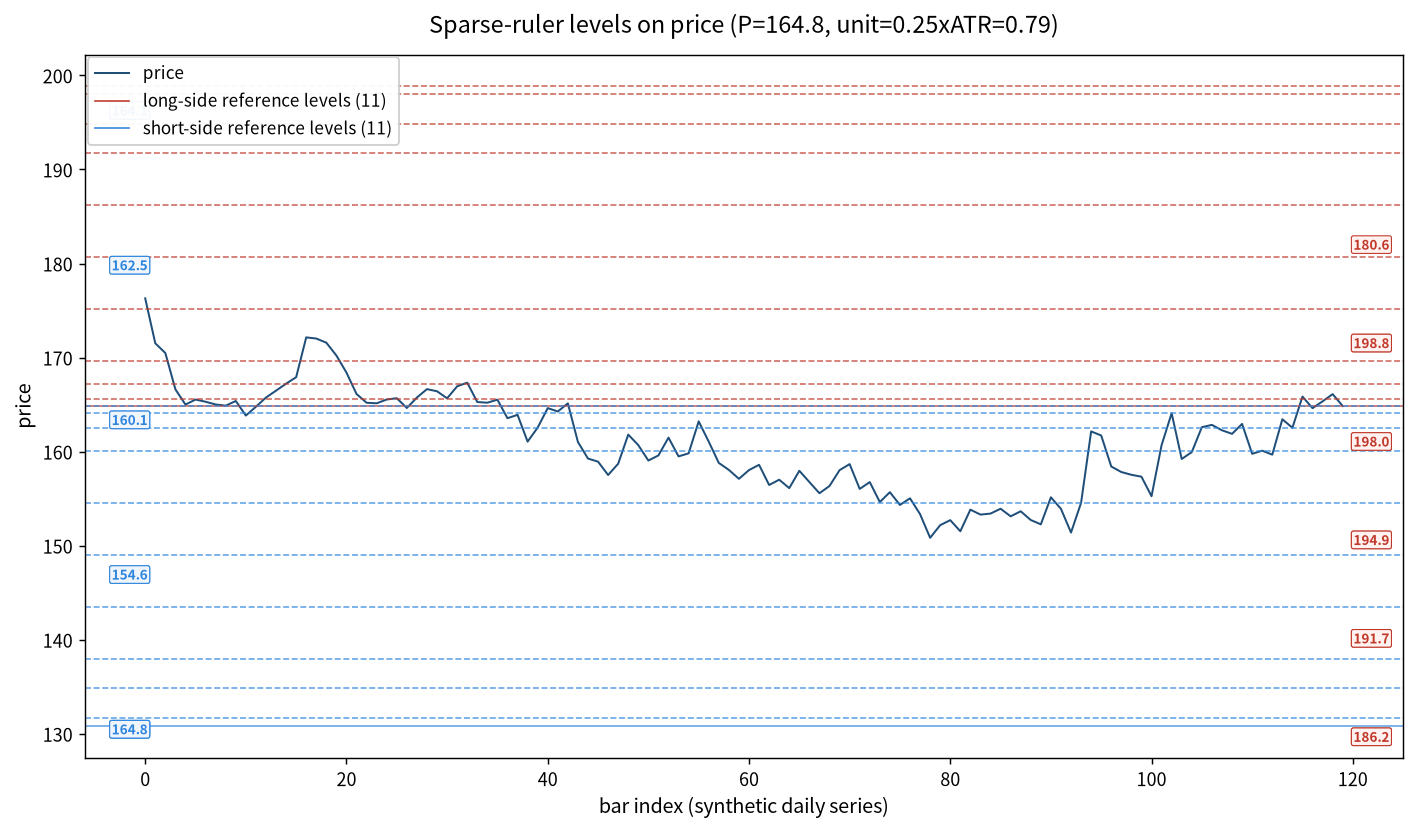

In [6]:
from IPython.display import Image, display

# Display the saved chart
display(Image('/content/ruler_levels.png'))

No .zip files found in /content. Displaying the default generated sparse-ruler chart:


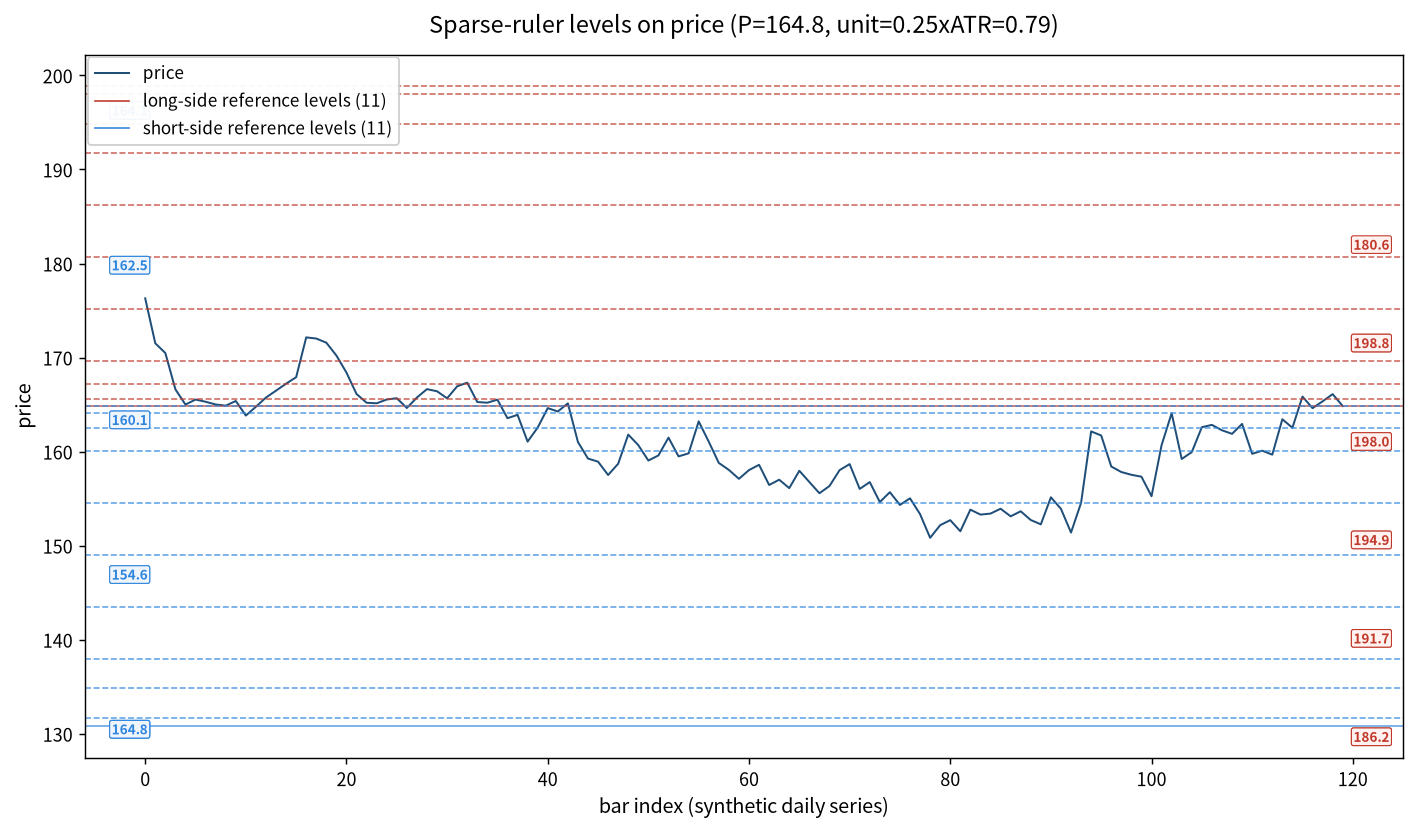

In [7]:
import os
import zipfile
from IPython.display import Image, display

# Check for zip files in the current workspace directory
files = os.listdir('/content')
zip_files = [f for f in files if f.endswith('.zip')]

if zip_files:
    print(f"Found zip file(s): {zip_files}")
    for z_file in zip_files:
        with zipfile.ZipFile(os.path.join('/content', z_file), 'r') as zip_ref:
            # List contents
            namelist = zip_ref.namelist()
            print(f"Contents of {z_file}: {namelist}")
            # Extract all files
            zip_ref.extractall('/content')
            # Look for any image files to display
            for name in namelist:
                if name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    print(f"Displaying extracted image: {name}")
                    display(Image(os.path.join('/content', name)))
else:
    print("No .zip files found in /content. Displaying the default generated sparse-ruler chart:")
    display(Image('/content/ruler_levels.png'))

from the zipped file